# Wikipedia Pageview Trend Analytics using Apache Spark

**Question:** *What was the world curious about, and when?*

We analyze **~470 million** Wikipedia page visits (hourly logs published by Wikimedia)
using **Apache Spark (PySpark)** to find:

1. The most viewed pages
2. How traffic changes hour by hour (time-series)
3. Desktop vs mobile usage
4. **Trending pages**, i.e. sudden spikes caused by news events
5. The most popular words in what people read (MapReduce word count with RDDs)

### Why is this Big Data? (5 Vs)
| V | In this project |
|---|---|
| **Volume** | ~6.5 million rows *per hour*, so 3 days is ~470 million rows (~4.2 GB compressed) |
| **Velocity** | A new file is published every hour, 24×7 (a clickstream log) |
| **Variety** | 300+ languages, Wikipedia + Wiktionary etc., desktop + mobile, junk/system pages |
| **Veracity** | Data is noisy: special pages, bots, broken titles, so we have to clean it |
| **Value** | Reveals real-world events and reading habits |

### Pipeline (Big Data Analytics Life Cycle)
```
Wikimedia dumps (.gz)  ->  [HDFS / local disk]  ->  Spark: Load -> Clean -> Aggregate (Parquet)
                                                         -> RDD MapReduce + Spark SQL analysis
                                                         -> results/*.csv  ->  Streamlit dashboard
```

## 1. Start Spark

In [1]:
import os, sys, time
os.environ["PYSPARK_PYTHON"] = sys.executable   # Spark workers use the same Python as this notebook

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("WikipediaPageviews")
         .master("local[*]")                    # use all CPU cores on this machine
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "40")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print("Cores used   :", spark.sparkContext.defaultParallelism)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/16 19:32:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.3
Cores used   : 10


## 2. Load the raw data

Each line of a file looks like: `en Virat_Kohli 2453 0` → *(project, page title, views, unused)*.

The **hour** isn't inside the file. It's in the file name (`pageviews-20260928-130000.gz`),
so we pull it out with `input_file_name()`.

> To read from **HDFS** instead of local disk, run `hdfs_upload.sh` and switch `DATA_PATH`.

In [2]:
DATA_PATH = "data/raw/*.gz"
# DATA_PATH = "hdfs://localhost:9000/wiki/raw/*.gz"   # <- if data is uploaded to HDFS

schema = "project STRING, title STRING, views LONG, unused LONG"

raw = (spark.read
       .csv(DATA_PATH, sep=" ", schema=schema)
       .withColumn("file", F.input_file_name()))

# pageviews-20260928-130000.gz  ->  2026-09-28 13:00:00
raw = raw.withColumn(
    "hour",
    F.to_timestamp(F.regexp_extract("file", r"pageviews-(\d{8}-\d{2})", 1), "yyyyMMdd-HH")
).drop("unused", "file")

raw.show(5, truncate=False)

+-------+---------------------------------------+-----+-------------------+
|project|title                                  |views|hour               |
+-------+---------------------------------------+-----+-------------------+
|NULL   |Category:Albanian                      |1    |2026-09-29 21:00:00|
|NULL   |Category:Candidates_for_speedy_deletion|1    |2026-09-29 21:00:00|
|NULL   |Category:Glossary                      |1    |2026-09-29 21:00:00|
|NULL   |Category:Noticeboards                  |1    |2026-09-29 21:00:00|
|NULL   |Category:Report_a_technical_problem/hu |1    |2026-09-29 21:00:00|
+-------+---------------------------------------+-----+-------------------+
only showing top 5 rows



In [3]:
start = time.time()
total_rows = raw.count()
load_seconds = time.time() - start

num_files = raw.select("hour").distinct().count()
print(f"Files (hours) : {num_files}")
print(f"Total rows    : {total_rows:,}")
print(f"Counted in    : {load_seconds:.1f} seconds  ({total_rows / load_seconds:,.0f} rows/sec)")
print(f"Partitions    : {raw.rdd.getNumPartitions()}  (gzip files can't be split, so 1 task per file)")

Files (hours) : 72
Total rows    : 467,322,549
Counted in    : 21.4 seconds  (21,806,328 rows/sec)
Partitions    : 48  (gzip files can't be split, so 1 task per file)


## 3. Explore: what is inside?

There's a lot of variety: many languages and projects. `en` = English Wikipedia (desktop), `en.m` = English Wikipedia (mobile).

In [4]:
(raw.groupBy("project")
    .agg(F.sum("views").alias("views"))
    .orderBy(F.desc("views"))
    .show(10))

+-------+---------+
|project|    views|
+-------+---------+
|   en.m|380205210|
|     en|240297740|
|   ja.m| 55932441|
|   de.m| 36509613|
|   ru.m| 33078167|
|   fr.m| 32298501|
|   es.m| 32264151|
|     ja| 29395138|
|     de| 27114561|
|   it.m| 23790566|
+-------+---------+
only showing top 10 rows



## 4. Clean the data

We keep **English Wikipedia** only (desktop + mobile) and remove noise:
- system pages like `Main_Page`, `Special:Search`, `-`
- non-article pages: `File:`, `Talk:`, `User:`, `Category:`, `Wikipedia:` ...

Then we **aggregate** desktop + mobile per page per hour and save as **Parquet**
(a compressed, columnar format, much faster to read than text).

In [5]:
junk_prefix = r"^(Special|File|Image|Wikipedia|Talk|User|User_talk|Category|Template|Help|Portal|Draft|Module|MediaWiki)(_talk)?:"

clean = (raw
         .filter(F.col("project").isin("en", "en.m"))
         .filter(~F.col("title").rlike(junk_prefix))
         .filter(~F.col("title").isin("Main_Page", "-", "undefined", "Search"))
         .filter(F.col("title").isNotNull())
         .withColumn("device", F.when(F.col("project") == "en", "Desktop").otherwise("Mobile"))
         .withColumn("title", F.regexp_replace("title", "_", " ")))

# one row per (page, hour, device)
hourly = clean.groupBy("title", "hour", "device").agg(F.sum("views").alias("views"))

start = time.time()
hourly.write.mode("overwrite").parquet("data/clean/hourly.parquet")
print(f"Cleaned + saved to Parquet in {time.time() - start:.1f} s")

Cleaned + saved to Parquet in 178.1 s


In [6]:
df = spark.read.parquet("data/clean/hourly.parquet").cache()
df.createOrReplaceTempView("pageviews")     # lets us use plain SQL below

clean_rows = df.count()
print(f"Rows after cleaning: {clean_rows:,}  (from {total_rows:,} raw rows)")
df.show(5, truncate=False)

Rows after cleaning: 149,044,966  (from 467,322,549 raw rows)
+-----------------------+-------------------+-------+-----+
|title                  |hour               |device |views|
+-----------------------+-------------------+-------+-----+
|!Decapitacion!         |2026-09-29 21:00:00|Desktop|1    |
|!Oka Tokat             |2026-09-29 21:00:00|Desktop|1    |
|!Tierra y Libertad!    |2026-09-29 21:00:00|Desktop|1    |
|!Ui language           |2026-09-29 21:00:00|Desktop|1    |
|!Vampiros en La Habana!|2026-09-29 21:00:00|Desktop|1    |
+-----------------------+-------------------+-------+-----+
only showing top 5 rows



## 5. Spark SQL analysis

Because we registered the data as a table called `pageviews`, we can query it with normal SQL,
and Spark runs it in parallel on all cores.

### 5.1 Overall numbers

In [7]:
summary = spark.sql("""
    SELECT COUNT(DISTINCT title) AS unique_pages,
           SUM(views)            AS total_views,
           MIN(hour)             AS first_hour,
           MAX(hour)             AS last_hour
    FROM pageviews
""").first()
summary

Row(unique_pages=10208605, total_views=575918015, first_hour=datetime.datetime(2026, 9, 28, 0, 0), last_hour=datetime.datetime(2026, 9, 30, 23, 0))

### 5.2 Top 25 most viewed pages

In [8]:
top_pages = spark.sql("""
    SELECT title, SUM(views) AS views
    FROM pageviews
    GROUP BY title
    ORDER BY views DESC
    LIMIT 25
""")
top_pages.show(25, truncate=False)

+--------------------------------+-------+
|title                           |views  |
+--------------------------------+-------+
|Christa Pike                    |1943096|
|Pac (wrestler)                  |1069806|
|Case Keenum                     |1032615|
|2026 Asian Games medal table    |877745 |
|Lizzie Borden                   |844105 |
|India at the 2026 Asian Games   |812423 |
|Ted Kaczynski                   |751888 |
|2026 Asian Games                |620802 |
|.xxx                            |434924 |
|Deaths in 2026                  |430740 |
|Dennis Haskins                  |351856 |
|Aileen Wuornos                  |335150 |
|Kate Upton                      |323630 |
|Justin Verlander                |292985 |
|The Paradise (2026 Indian film) |292389 |
|Digger (2026 film)              |274152 |
|Primetime (film)                |271614 |
|Neatsville, Kentucky            |258619 |
|Lanterns (TV series)            |257756 |
|Cornell 7                       |255703 |
|Monster: T

### 5.3 Traffic per hour (time-series), desktop vs mobile

In [9]:
hourly_traffic = spark.sql("""
    SELECT hour, device, SUM(views) AS views
    FROM pageviews
    GROUP BY hour, device
    ORDER BY hour
""")
hourly_traffic.show(6)

+-------------------+-------+-------+
|               hour| device|  views|
+-------------------+-------+-------+
|2026-09-28 00:00:00| Mobile|5941708|
|2026-09-28 00:00:00|Desktop|2510771|
|2026-09-28 01:00:00|Desktop|2630048|
|2026-09-28 01:00:00| Mobile|6501151|
|2026-09-28 02:00:00| Mobile|6851836|
|2026-09-28 02:00:00|Desktop|2703118|
+-------------------+-------+-------+
only showing top 6 rows



### 5.4 Desktop vs mobile share

In [10]:
device_split = spark.sql("""
    SELECT device, SUM(views) AS views
    FROM pageviews
    GROUP BY device
""")
device_split.show()

+-------+---------+
| device|    views|
+-------+---------+
|Desktop|209294612|
| Mobile|366623403|
+-------+---------+



### 5.5 Trending pages (spike detection)

A page is **trending** if its busiest hour is far above its normal hour.

    spike score = peak hour views ÷ average hourly views

We only consider pages with at least 5,000 views in their peak hour, so tiny pages with random jumps are ignored.

In [11]:
num_hours = df.select("hour").distinct().count()

trending = spark.sql(f"""
    WITH per_hour AS (
        SELECT title, hour, SUM(views) AS views
        FROM pageviews
        GROUP BY title, hour
    ),
    stats AS (
        SELECT title,
               MAX(views)              AS peak_views,
               SUM(views) / {num_hours} AS avg_views,
               MAX_BY(hour, views)     AS peak_hour,
               SUM(views)              AS total_views
        FROM per_hour
        GROUP BY title
    )
    SELECT title, peak_hour, peak_views,
           ROUND(avg_views)              AS avg_views,
           ROUND(peak_views / avg_views, 1) AS spike_score,
           total_views
    FROM stats
    WHERE peak_views >= 5000
    ORDER BY spike_score DESC
    LIMIT 30
""")
trending.show(30, truncate=False)

+------------------------------------------------------------------+-------------------+----------+---------+-----------+-----------+
|title                                                             |peak_hour          |peak_views|avg_views|spike_score|total_views|
+------------------------------------------------------------------+-------------------+----------+---------+-----------+-----------+
|Joseph Cafazzo                                                    |2026-09-30 22:00:00|10068     |140.0    |71.8       |10101      |
|Kars                                                              |2026-09-28 22:00:00|8296      |131.0    |63.2       |9450       |
|J. R. Ewing                                                       |2026-09-28 21:00:00|18414     |299.0    |61.7       |21494      |
|Cindy Blackman Santana                                            |2026-09-29 01:00:00|12185     |211.0    |57.7       |15198      |
|KaVontae Turpin                                              

### 5.6 Heatmap data: when does each top page get read?

For the top 15 pages, total views per hour of the day (UTC).

In [12]:
top15 = [r.title for r in top_pages.limit(15).collect()]

heatmap = (df.filter(F.col("title").isin(top15))
             .withColumn("hour_of_day", F.hour("hour"))
             .groupBy("title", "hour_of_day")
             .agg(F.sum("views").alias("views")))
heatmap.orderBy("title", "hour_of_day").show(5)

+-----+-----------+-----+
|title|hour_of_day|views|
+-----+-----------+-----+
| .xxx|          0| 9659|
| .xxx|          1| 8901|
| .xxx|          2|10213|
| .xxx|          3| 8791|
| .xxx|          4|12141|
+-----+-----------+-----+
only showing top 5 rows



## 6. MapReduce with RDDs: most popular words

This is the classic **word count**, but each word is weighted by how many views its page got.

- **Map:** `"Taylor Swift" (1,000 views)` → `("taylor", 1000), ("swift", 1000)`
- **Reduce:** add up the views for each word across all pages

In [13]:
import re

stopwords = {"the", "of", "and", "in", "for", "on", "at", "by", "an", "from", "with",
             "film", "list", "season", "series", "episodes", "characters", "song", "album"}

def words(title):
    # "Oppenheimer (2023 film)" -> ["oppenheimer", "2023", "film"]
    return re.findall(r"[a-z]+", title.lower())

page_totals = df.groupBy("title").agg(F.sum("views").alias("views"))

word_counts = (page_totals.rdd
               .flatMap(lambda row: [(w, row.views) for w in words(row.title)])   # MAP
               .filter(lambda kv: kv[0] not in stopwords and len(kv[0]) > 2)
               .reduceByKey(lambda a, b: a + b)                                   # REDUCE
               .sortBy(lambda kv: -kv[1]))

top_words = word_counts.take(30)
for word, views in top_words[:10]:
    print(f"{word:<15} {views:>12,}")

games              5,949,713
united             5,433,892
asian              5,253,574
states             4,446,819
john               4,055,459
american           3,951,340
world              3,702,604
football           3,536,144
election           3,108,361
new                3,097,098


## 7. Save results for the dashboard

The results are small (a few thousand rows), so we convert them to Pandas and save as CSV.
The Streamlit dashboard reads these files, so it loads instantly and doesn't need Spark running.

In [14]:
import json
os.makedirs("results", exist_ok=True)

raw_gb = sum(os.path.getsize(os.path.join("data/raw", f)) for f in os.listdir("data/raw")) / 1e9

json.dump({
    "raw_rows": total_rows,
    "clean_rows": clean_rows,
    "files": num_files,
    "raw_gb": round(raw_gb, 2),
    "unique_pages": summary.unique_pages,
    "total_views": summary.total_views,
    "first_hour": str(summary.first_hour),
    "last_hour": str(summary.last_hour),
    "load_seconds": round(load_seconds, 1),
    "cores": spark.sparkContext.defaultParallelism,
}, open("results/summary.json", "w"), indent=2)

top_pages.toPandas().to_csv("results/top_pages.csv", index=False)
hourly_traffic.toPandas().to_csv("results/hourly_traffic.csv", index=False)
device_split.toPandas().to_csv("results/device_split.csv", index=False)
trending.toPandas().to_csv("results/trending.csv", index=False)
heatmap.toPandas().to_csv("results/heatmap.csv", index=False)
spark.createDataFrame(top_words, ["word", "views"]).toPandas().to_csv("results/top_words.csv", index=False)

# hourly time-series for the top 300 pages + all trending pages (for the "search a page" feature)
keep = [r.title for r in page_totals.orderBy(F.desc("views")).limit(300).collect()]
keep += [r.title for r in trending.collect()]
(df.filter(F.col("title").isin(keep))
   .groupBy("title", "hour").agg(F.sum("views").alias("views"))
   .toPandas().to_csv("results/page_hourly.csv", index=False))

print("Saved:", sorted(os.listdir("results")))

Saved: ['device_split.csv', 'heatmap.csv', 'hourly_traffic.csv', 'page_hourly.csv', 'summary.json', 'top_pages.csv', 'top_words.csv', 'trending.csv']


## 8. Quick charts

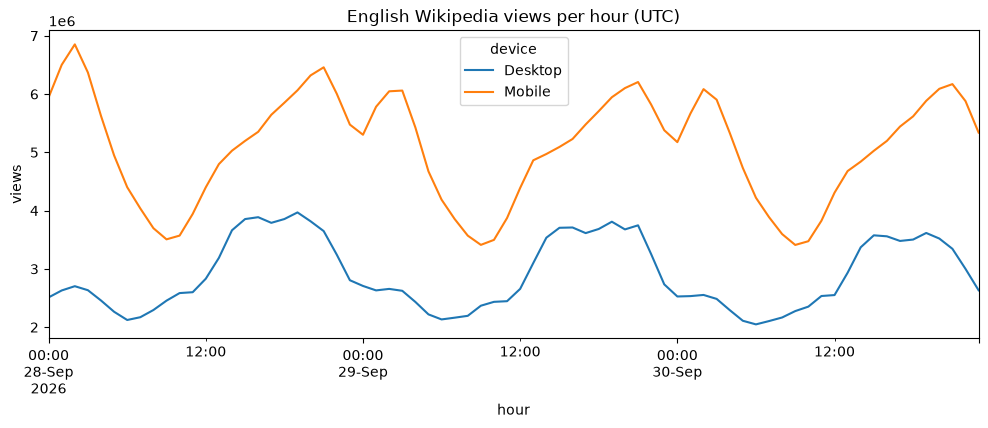

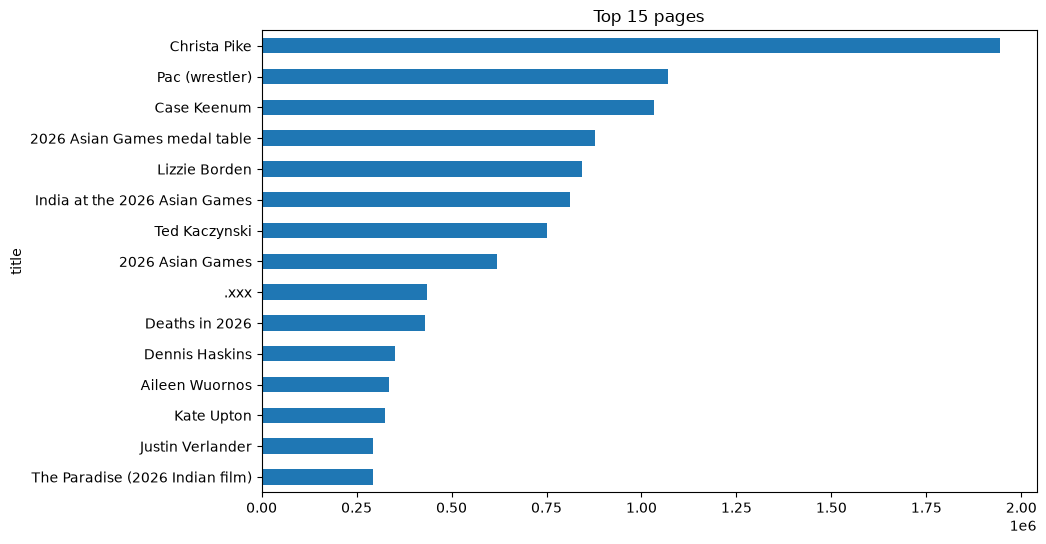

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

ht = pd.read_csv("results/hourly_traffic.csv", parse_dates=["hour"])
ht.pivot(index="hour", columns="device", values="views").plot(figsize=(12, 4), title="English Wikipedia views per hour (UTC)")
plt.ylabel("views"); plt.show()

tp = pd.read_csv("results/top_pages.csv").head(15).iloc[::-1]
tp.plot.barh(x="title", y="views", figsize=(10, 6), legend=False, title="Top 15 pages")
plt.show()

## 9. Conclusions

- Spark processed **hundreds of millions of rows** on a single laptop by running work in parallel on every CPU core.
- **Mobile** has more views than desktop on English Wikipedia.
- Traffic follows a clear **daily cycle** (lowest around 08:00–10:00 UTC, when the Americas are asleep).
- **Spike detection** surfaces news events (deaths, sports matches, releases) without any manual labelling.
- Saving cleaned data as **Parquet** made repeated analysis much faster than re-reading gzip text.

**Run the dashboard:** `streamlit run app.py`

In [16]:
spark.stop()